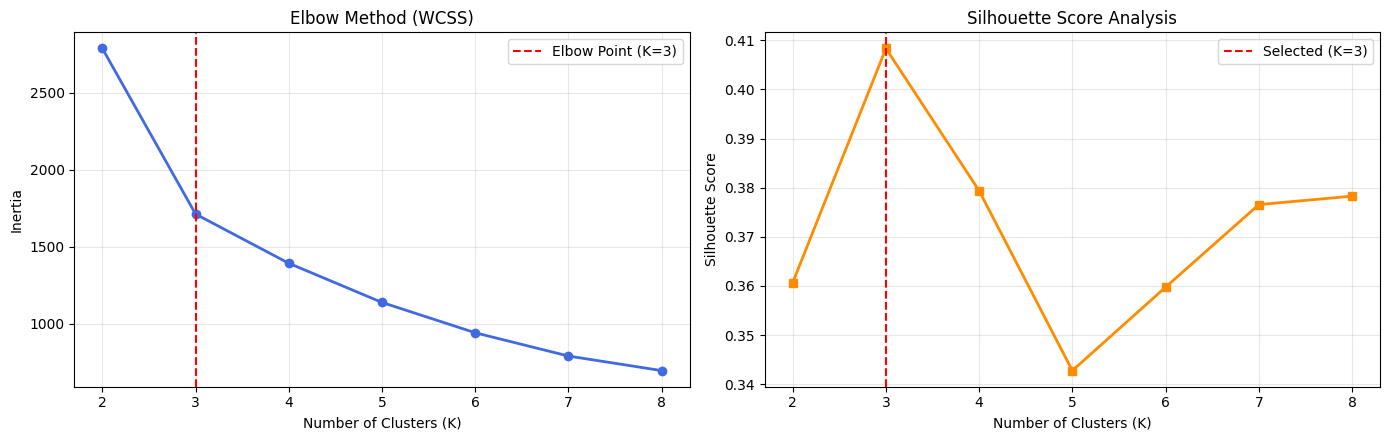

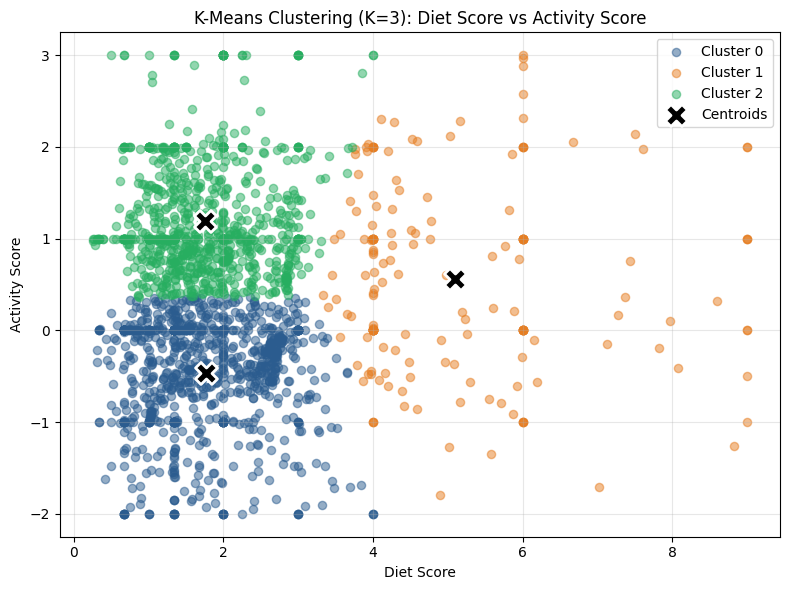

Centroids Interpretation (Original Units):
         Diet_Score  Activity_Score  Size  \
Cluster                                     
0              1.76           -0.46   996   
1              5.10            0.56   184   
2              1.75            1.20   907   

                                                   Profile  
Cluster                                                     
0        Low diet quality, sedentary profile (Couch pot...  
1        High diet quality, active lifestyle (Health-co...  
2        Low diet quality, high physical activity (Acti...  

Algorithm Comparison Table:
            Algorithm  Clusters Found  Silhouette Score
0  K-Means (Selected)               3            0.4083
1           K-Medoids               3            0.3666
2              DBSCAN               5            0.2277


In [9]:
!pip install scikit-learn-extra -q

# ============================================================
# PART 1: IMPORTS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn_extra.cluster import KMedoids

RANDOM_STATE = 42

# ============================================================
# PART 2: DATA LOADING AND CLEANING
# ============================================================
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
df = df.drop_duplicates()

# ============================================================
# PART 3: FEATURE ENGINEERING & SCALING
# ============================================================
df['Diet_Score'] = (df['FCVC'] * df['CH2O']) / df['NCP']
df['Activity_Score'] = df['FAF'] - df['TUE']

features_clustering = ['Diet_Score', 'Activity_Score']
X_cluster = df[features_clustering].copy()

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# ============================================================
# PART 4: EVALUATING K-MEANS (K = 2 TO 8: ELBOW & SILHOUETTE)
# ============================================================
K_range = range(2, 9)
inertias = []
sil_scores = []
db_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster_scaled, labels))
    db_scores.append(davies_bouldin_score(X_cluster_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].plot(K_range, inertias, marker='o', color='royalblue', lw=2)
ax[0].axvline(x=3, color='red', linestyle='--', label='Elbow Point (K=3)')
ax[0].set_title('Elbow Method (WCSS)')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('Inertia')
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(K_range, sil_scores, marker='s', color='darkorange', lw=2)
ax[1].axvline(x=3, color='red', linestyle='--', label='Selected (K=3)')
ax[1].set_title('Silhouette Score Analysis')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

# ============================================================
# PART 5: FINAL K-MEANS MODEL (K = 3) AND PROFILES
# ============================================================
K_FINAL = 3
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=20)
df['cluster'] = kmeans_final.fit_predict(X_cluster_scaled)

colors = ['#2b5c8f', '#e67e22', '#27ae60']
plt.figure(figsize=(8, 6))

for i in range(K_FINAL):
    subset = df[df['cluster'] == i]
    plt.scatter(
        subset['Diet_Score'], subset['Activity_Score'],
        color=colors[i], label=f'Cluster {i}', alpha=0.5, s=35
    )

centroids_orig = scaler_cluster.inverse_transform(kmeans_final.cluster_centers_)
plt.scatter(
    centroids_orig[:, 0], centroids_orig[:, 1],
    c='black', marker='X', s=250, label='Centroids', edgecolor='white', linewidth=2
)

plt.title('K-Means Clustering (K=3): Diet Score vs Activity Score')
plt.xlabel('Diet Score')
plt.ylabel('Activity Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Centroids Interpretation Table
# Centroids Interpretation Table
centroids_df = pd.DataFrame(centroids_orig, columns=features_clustering)
centroids_df['Size'] = df['cluster'].value_counts().sort_index().values
centroids_df['Profile'] = [
    'Low diet quality, sedentary profile (Couch potato)',
    'High diet quality, active lifestyle (Health-conscious)',
    'Low diet quality, high physical activity (Active fast-food fan)'
]
centroids_df.index.name = 'Cluster'
print("Centroids Interpretation (Original Units):")
print(centroids_df.round(2))

# ============================================================
# PART 6: COMPARISON WITH K-MEDOIDS AND DBSCAN (BACKGROUND/CODE)
# ============================================================
# K-Medoids
kmedoids = KMedoids(n_clusters=3, random_state=RANDOM_STATE)
labels_kmedoids = kmedoids.fit_predict(X_cluster_scaled)
sil_kmedoids = silhouette_score(X_cluster_scaled, labels_kmedoids)

# DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=10)
labels_dbscan = dbscan.fit_predict(X_cluster_scaled)
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)

comparison_table = pd.DataFrame({
    'Algorithm': ['K-Means (Selected)', 'K-Medoids', 'DBSCAN'],
    'Clusters Found': [3, 3, n_clusters_dbscan],
    'Silhouette Score': [
        round(silhouette_score(X_cluster_scaled, kmeans_final.labels_), 4),
        round(sil_kmedoids, 4),
        round(silhouette_score(X_cluster_scaled, labels_dbscan) if n_clusters_dbscan > 1 else 0, 4)
    ]
})
print("\nAlgorithm Comparison Table:")
print(comparison_table)